# Step 4: Baseline Model - Generalized Linear Model (GLM)
## AI-Assisted Health Risk Prediction for Life Insurance Underwriting

We fit **Logistic Regression** - a GLM with a Binomial family and logit link.
This is the actuarial industry standard for binary underwriting decisions and
serves as our **interpretable benchmark** to compare with XGBoost and the neural network
(Steps 5).

**Why logistic regression (not Poisson/Gamma)?** Our target `MORTSTAT` is binary
(0=alive, 1=deceased). Poisson is for counts; Gamma for positive continuous
values. Logistic regression is the correct GLM for a 0/1 outcome.

**This notebook:**
1. Load model-ready data + metadata from Step 3
2. Train logistic regression with balanced class weights
3. Evaluate: AUROC, PR-AUC, F1 (+ confusion matrix, curves)
4. Interpret coefficients (odds ratios) — which factors drive mortality risk
5. Save metrics + model for cross-model comparison in later steps

## 4.1 Setup & Load Model-Ready Data

In [1]:
import pandas as pd
import numpy as np
import json
import joblib
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             classification_report)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
print('Imports OK')

Imports OK


In [2]:
# Robust path resolution (works from project root or Code/)
def find_dir(name):
    for base in [Path('.'), Path('..'), Path('..') / '..']:
        candidate = base / 'data' / name
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(f'Could not locate data/{name}. Run notebook 03 first.')

MODEL_DIR = find_dir('model_ready')
print(f'Model-ready dir: {MODEL_DIR}')

# Load processed matrices
X_train = pd.read_parquet(MODEL_DIR / 'X_train.parquet')
X_test = pd.read_parquet(MODEL_DIR / 'X_test.parquet')
y_train = pd.read_parquet(MODEL_DIR / 'y_train.parquet')['MORTSTAT']
y_test = pd.read_parquet(MODEL_DIR / 'y_test.parquet')['MORTSTAT']

with open(MODEL_DIR / 'preprocessing_metadata.json') as f:
    meta = json.load(f)

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Train mortality rate: {y_train.mean():.4f}')
print(f'Test  mortality rate: {y_test.mean():.4f}')
print(f'scale_pos_weight (from EDA): {meta["scale_pos_weight"]}')

Model-ready dir: <PROJECT_ROOT>\data\model_ready
X_train: (14862, 84), X_test: (3716, 84)
Train mortality rate: 0.1408
Test  mortality rate: 0.1407
scale_pos_weight (from EDA): 6.104


## 4.2 Train Logistic Regression

`class_weight='balanced'` automatically weights the minority (deceased) class
inversely to its frequency - this is how we handle the ~14% imbalance without
resampling. We use L2 regularization and a high `max_iter` for convergence.

In [3]:
glm = LogisticRegression(
    class_weight='balanced',   # handles class imbalance (deceased ~14%)
    max_iter=2000,
    C=1.0,                     # inverse regularization strength
    solver='lbfgs',
    random_state=RANDOM_STATE,
)
glm.fit(X_train, y_train)
print('Model trained.')
print(f'Converged in {glm.n_iter_[0]} iterations.')

Model trained.
Converged in 69 iterations.


## 4.3 Evaluate on the Test Set

Primary metrics (chosen for imbalanced classification):
- **AUROC** - ranking/discrimination ability
- **PR-AUC** (average precision) - more informative than AUROC under imbalance
- **F1** - balance of precision & recall for the positive (deceased) class

In [4]:
# Predicted probabilities and labels
y_prob = glm.predict_proba(X_test)[:, 1]
y_pred = glm.predict(X_test)

auroc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
f1 = f1_score(y_test, y_pred)

print('=' * 45)
print('GLM (Logistic Regression) — Test Metrics')
print('=' * 45)
print(f'AUROC   : {auroc:.4f}')
print(f'PR-AUC  : {pr_auc:.4f}')
print(f'F1      : {f1:.4f}')
print()
print('Classification report:')
print(classification_report(y_test, y_pred, target_names=['Alive', 'Deceased']))

GLM (Logistic Regression) — Test Metrics
AUROC   : 0.9039
PR-AUC  : 0.6490
F1      : 0.5794

Classification report:
              precision    recall  f1-score   support

       Alive       0.97      0.83      0.89      3193
    Deceased       0.44      0.84      0.58       523

    accuracy                           0.83      3716
   macro avg       0.71      0.83      0.74      3716
weighted avg       0.89      0.83      0.85      3716



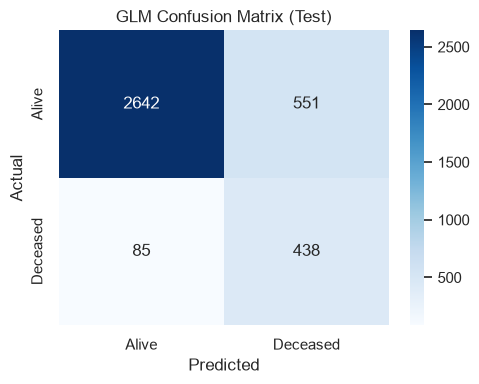

In [5]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Alive', 'Deceased'],
            yticklabels=['Alive', 'Deceased'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('GLM Confusion Matrix (Test)')
plt.tight_layout()
plt.show()

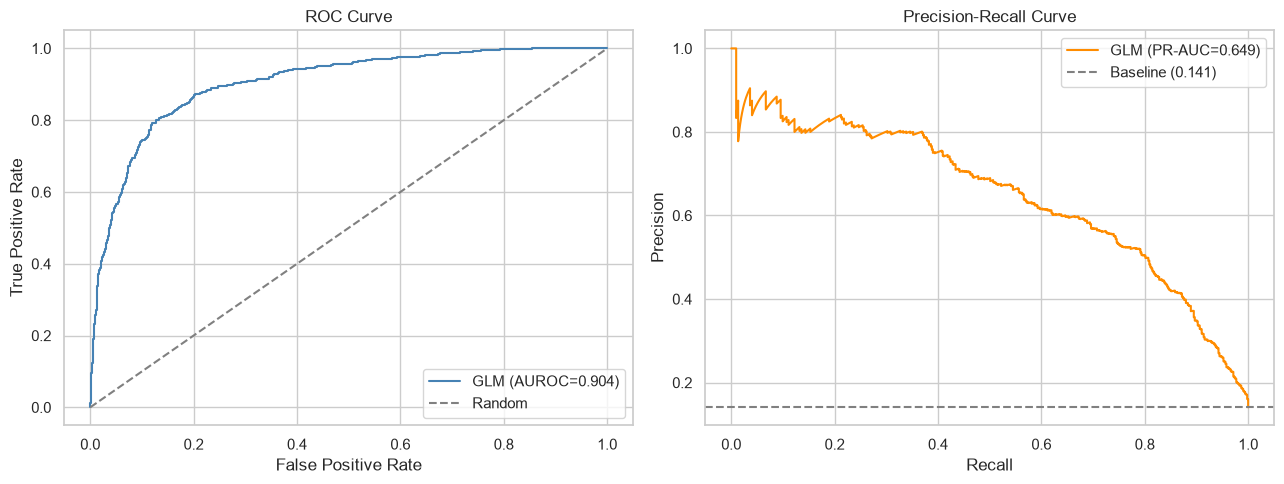

In [6]:
# ROC and PR curves
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[0].plot(fpr, tpr, label=f'GLM (AUROC={auroc:.3f})', color='steelblue')
ax[0].plot([0, 1], [0, 1], '--', color='gray', label='Random')
ax[0].set_xlabel('False Positive Rate')
ax[0].set_ylabel('True Positive Rate')
ax[0].set_title('ROC Curve')
ax[0].legend()

prec, rec, _ = precision_recall_curve(y_test, y_prob)
baseline = y_test.mean()
ax[1].plot(rec, prec, label=f'GLM (PR-AUC={pr_auc:.3f})', color='darkorange')
ax[1].axhline(baseline, ls='--', color='gray', label=f'Baseline ({baseline:.3f})')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-Recall Curve')
ax[1].legend()

plt.tight_layout()
# Save for the ACM report
FIG_DIR = MODEL_DIR.parent / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG_DIR / 'glm_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.4 Coefficient Interpretation (Odds Ratios)

The key advantage of a GLM is interpretability. Each coefficient (beta) means:
a one-unit increase in the (standardized) feature multiplies the **odds of death**
by `exp(beta)`. Odds ratio > 1 => increases risk; < 1 => protective.

In [8]:
coefs = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': glm.coef_[0],
})
coefs['odds_ratio'] = np.exp(coefs['coefficient'])
coefs['abs_coef'] = coefs['coefficient'].abs()
coefs = coefs.sort_values('abs_coef', ascending=False).drop(columns='abs_coef')

print('Top 15 most influential features (by |coefficient|):')
coefs.head(15).reset_index(drop=True)

Top 15 most influential features (by |coefficient|):


,feature,coefficient,odds_ratio
0,num__AGE,1.465676,4.330470
1,cat__RACE_ETHNICITY_3.0,0.531517,1.701512
2,num__BMXBMI,-0.451650,0.636577
3,cat__MCQ160B_2.0,-0.394627,0.673931
4,cat__MARITAL_STATUS_1.0,-0.389188,0.677607
5,cat__MCQ160B_1.0,0.381330,1.464231
6,num__URXUMA,0.369238,1.446631
7,cat__RACE_ETHNICITY_1.0,-0.357355,0.699524
8,num__BMXWT,0.349737,1.418694
9,cat__GENDER_2.0,-0.346096,0.707444


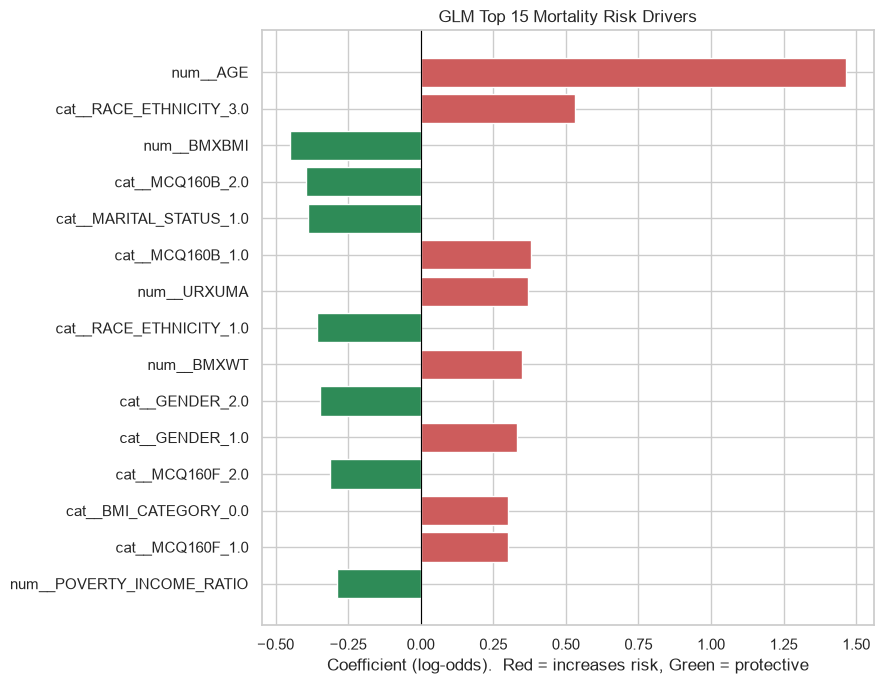

In [9]:
# Plot top drivers (positive = risk, negative = protective)
top = coefs.head(15).iloc[::-1]
colors = ['indianred' if c > 0 else 'seagreen' for c in top['coefficient']]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top['feature'], top['coefficient'], color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Coefficient (log-odds).  Red = increases risk, Green = protective')
ax.set_title('GLM Top 15 Mortality Risk Drivers')
plt.tight_layout()
plt.savefig(FIG_DIR / 'glm_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.5 Save Model & Metrics

We persist the trained GLM and its metrics to a shared results file that
later notebooks append to, enabling a single cross-model comparison table.

In [10]:
RESULTS_DIR = MODEL_DIR.parent / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained model
joblib.dump(glm, RESULTS_DIR / 'glm_model.joblib')

# Save/append metrics to a shared comparison file
metrics_path = RESULTS_DIR / 'model_metrics.json'
all_metrics = {}
if metrics_path.exists():
    with open(metrics_path) as f:
        all_metrics = json.load(f)

all_metrics['GLM_LogisticRegression'] = {
    'auroc': round(float(auroc), 4),
    'pr_auc': round(float(pr_auc), 4),
    'f1': round(float(f1), 4),
    'n_test': int(len(y_test)),
}
with open(metrics_path, 'w') as f:
    json.dump(all_metrics, f, indent=2)

# Also save GLM coefficients (useful for the report + SHAP comparison later)
coefs.to_csv(RESULTS_DIR / 'glm_coefficients.csv', index=False)

print('Saved:')
print(f'  - {RESULTS_DIR / "glm_model.joblib"}')
print(f'  - {metrics_path}')
print(f'  - {RESULTS_DIR / "glm_coefficients.csv"}')
print('\nCurrent model comparison:')
print(json.dumps(all_metrics, indent=2))

Saved:
  - <PROJECT_ROOT>\data\results\glm_model.joblib
  - <PROJECT_ROOT>\data\results\model_metrics.json
  - <PROJECT_ROOT>\data\results\glm_coefficients.csv

Current model comparison:
{
  "GLM_LogisticRegression": {
    "auroc": 0.9039,
    "pr_auc": 0.649,
    "f1": 0.5794,
    "n_test": 3716
  },
  "XGBoost": {
    "auroc": 0.907,
    "pr_auc": 0.6633,
    "f1": 0.6128,
    "n_test": 3716
  },
  "NeuralNetwork": {
    "auroc": 0.9029,
    "pr_auc": 0.6525,
    "f1": 0.5599,
    "n_test": 3716
  }
}


## Interpretation & Next Steps

**What the baseline tells us:**
- AUROC around 0.8+ is expected — age alone is a very strong signal
- The coefficient plot shows which factors the linear model relies on (age, blood pressure, creatinine, etc.)
- This is our benchmark. If XGBoost/NN can't beat it meaningfully, the added complexity isn't justified.

**Proceed to Notebook 05: Machine Learning Models (XGBoost + Neural Network)**
- Reuse the same `X_train`/`X_test` and `scale_pos_weight`
- Append their metrics to `data/results/model_metrics.json` for direct comparison